# Q1, analysis 2: perceptual RDM vs. the Kriegeskorte (2008b) / Mur (2013) data

Reads the CSVs written by `python -m analysis.build_rdms.run_k92` (`analysis/results/kriegeskorte92/`).

The external data (rsagroup/rsatoolbox `demos/92imageData/`) has no image IDs, so overlap with our Kiani-sourced images was found by category-restricted average-hash matching and **confirmed by visual review**: 42 of the 92 images (hamming <= 10 and pixel MAE < 5, a clean gap to the forced leftovers; 0 human faces, since none of our Kiani images are faces). Targets: Mur 2013 similarity judgments (16 participants, primary), human IT fMRI (8 RDMs) and monkey IT (secondary). Kendall tau-a is primary; permutation nulls relabel image identity; the bootstrap resamples our participants. Small N (861 pairs, about 535 observed by our participants): read CIs, not just p-values.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from PIL import Image
from IPython.display import display

from analysis.build_rdms import kriegeskorte92 as k92
from analysis.build_rdms.common import REPO_ROOT, image_paths
from analysis.utils.plotting import role_palette

D = REPO_ROOT / "analysis" / "results" / "kriegeskorte92"
T = {n: pd.read_csv(D / f"k92_{n}.csv") for n in ["summary", "permutation", "gamma", "gamma_shuffle", "hdbscan", "fdr"]}
overlap = pd.read_csv(D / "approved_matches.csv")
COHORTS = ["pre", "post"]
LABEL = {"pre": "Pre-SHINE", "post": "Post-SHINE"}
COLOR = {c: v["violin_line"] if "violin_line" in v else list(v.values())[0] for c, v in role_palette(COHORTS).items()}
TARGET = {"behavioral_mur2013": "Mur 2013 judgments", "hIT_kriegeskorte2008": "Human IT (fMRI)", "mIT_kriegeskorte2008": "Monkey IT"}
pd.set_option("display.width", 200)

## Overlap

In [2]:
print(len(overlap), "approved images")
overlap.groupby("ext_category").size().rename("n").to_frame().T

42 approved images


ext_category,artificial inanimate,human bodypart,natural inanimate,nonhuman bodypart,nonhuman face
n,10,5,19,2,6


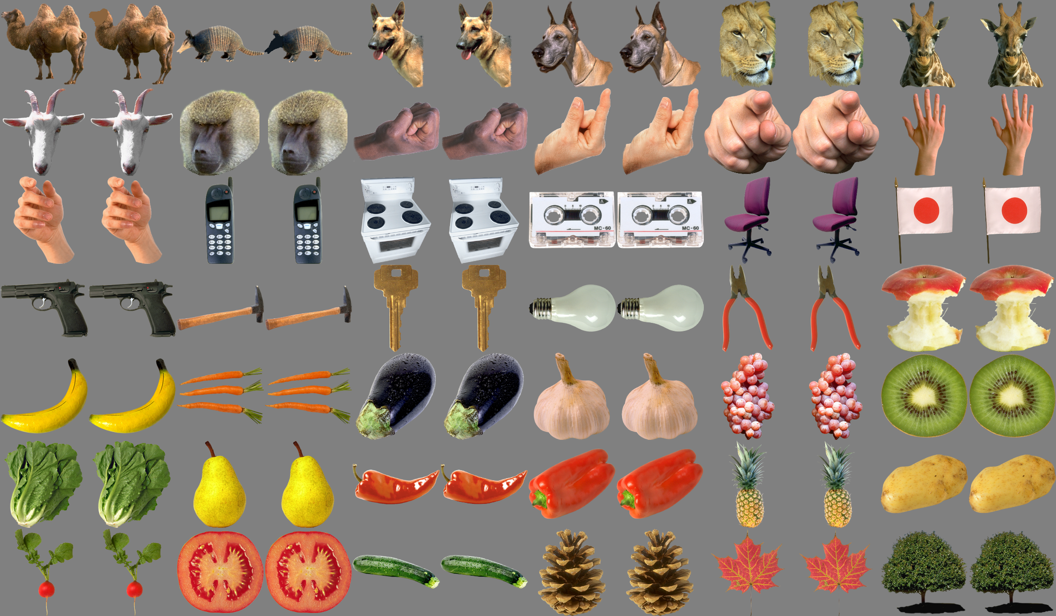

In [3]:
paths = image_paths("pre_shine")
stimuli = k92.load_stimuli()
tiles = []
for _, r in overlap.iterrows():
    ext = np.asarray(Image.fromarray(stimuli.images[int(r["ext_index"])]).resize((88, 88)))
    ours = np.asarray(Image.fromarray(k92.load_our_image(paths[int(r["manifest_row"])])).resize((88, 88)))
    tiles.append(np.hstack([ext, ours]))
while len(tiles) % 6:
    tiles.append(np.full_like(tiles[0], 255))
grid = np.vstack([np.hstack(tiles[i:i + 6]) for i in range(0, len(tiles), 6)])
display(Image.fromarray(grid))  # each tile: 92-dataset image | ours

## RDM-level agreement

In [4]:
T["summary"].set_index(["cohort", "target"]).T.round(4)

cohort                                 pre                                                         post                                          
target                  behavioral_mur2013 hIT_kriegeskorte2008 mIT_kriegeskorte2008 behavioral_mur2013 hIT_kriegeskorte2008 mIT_kriegeskorte2008
n_images                           42.0000              42.0000              42.0000            42.0000              42.0000              42.0000
n_pairs                           861.0000             861.0000             861.0000           861.0000             861.0000             861.0000
n_pairs_observed                  536.0000             536.0000             536.0000           534.0000             534.0000             534.0000
n_external_rdms                    16.0000               8.0000               1.0000            16.0000               8.0000               1.0000
tau_a                               0.2584               0.1284               0.1574             0.2697               0.1500               0.1729
spearman                            0.3816               0.1947               0.2341             0.4044               0.2258               0.2610
perm_p_tau_a                        0.0002               0.0002               0.0002             0.0002               0.0002               0.0002
boot_ours_ci_lo                     0.2025               0.0916               0.1207             0.2044               0.0932               0.1104
boot_ours_ci_hi                     0.2934               0.1648               0.1944             0.2999               0.1795               0.2076
mean_per_external_tau_a             0.2044               0.0657               0.1574             0.2358               0.0718               0.1729
boot_external_ci_lo                 0.1822               0.0465                  NaN             0.2069               0.0375                  NaN
boot_external_ci_hi                 0.2207               0.0816                  NaN             0.2571               0.1032                  NaN
external_loo_tau_a                  0.3555               0.1291                  NaN             0.3555               0.1291                  NaN
external_vs_km_tau_a                0.4096               0.3099               0.3021             0.4096               0.3099               0.3021
ours_vs_km_tau_a                    0.2314               0.2314               0.2314             0.2580               0.2580               0.2580

In [5]:
T["fdr"].round(4)

,cohort,test,p_value,p_fdr
0,pre,tau_a_permutation_behavioral_mur2013,0.0002,0.0002
1,pre,tau_a_permutation_hIT_kriegeskorte2008,0.0002,0.0002
2,pre,tau_a_permutation_mIT_kriegeskorte2008,0.0002,0.0002
3,pre,ours_vs_external_average,0.0002,0.0002
4,pre,ours_vs_external_complete,0.0002,0.0002
5,post,tau_a_permutation_behavioral_mur2013,0.0002,0.0002
6,post,tau_a_permutation_hIT_kriegeskorte2008,0.0002,0.0002
7,post,tau_a_permutation_mIT_kriegeskorte2008,0.0002,0.0002
8,post,ours_vs_external_average,0.0002,0.0002
9,post,ours_vs_external_complete,0.0002,0.0002


Points are the combined-RDM tau-a with its participant-bootstrap 95% CI. The grey marker is the Mur participants' leave-one-out ceiling (how well a single external participant is predicted by the other 15), shown for that target only; it is a different quantity from our combined-RDM value, so it marks headroom rather than a strict cap.

In [6]:
fig = go.Figure()
for c in COHORTS:
    d = T["summary"].query("cohort == @c").set_index("target").loc[list(TARGET)]
    fig.add_trace(go.Scatter(
        x=[TARGET[t] for t in d.index], y=d["tau_a"], mode="markers", name=LABEL[c], marker=dict(color=COLOR[c], size=11),
        error_y=dict(type="data", symmetric=False, array=d["boot_ours_ci_hi"] - d["tau_a"], arrayminus=d["tau_a"] - d["boot_ours_ci_lo"])))
ceil = T["summary"].query("target == 'behavioral_mur2013'")["external_loo_tau_a"].iloc[0]
fig.add_trace(go.Scatter(x=[TARGET["behavioral_mur2013"]], y=[ceil], mode="markers", name="Mur LOO ceiling",
                         marker=dict(color="grey", symbol="line-ew", size=26, line=dict(width=3))))
fig.update_layout(template="plotly_white", height=460, yaxis_title="Kendall tau-a (ours vs. external)",
                  title="Perceptual RDM vs. external RDMs on the 42 overlapping images")
fig

Context: the same images scored against the KM tree. If the external data agree with KM about as much as ours do, the comparison is not driven by something specific to our RDM.

In [7]:
T["summary"].pivot(index="target", columns="cohort", values=["ours_vs_km_tau_a", "external_vs_km_tau_a"]).round(3)

ours_vs_km_tau_a        external_vs_km_tau_a       
cohort                           post    pre                 post    pre
target                                                                  
behavioral_mur2013              0.258  0.231                0.410  0.410
hIT_kriegeskorte2008            0.258  0.231                0.310  0.310
mIT_kriegeskorte2008            0.258  0.231                0.302  0.302

## Whole-tree agreement (agglomerative, MDS embeddings restricted to the overlap)

In [8]:
T["gamma_shuffle"].round(4)

,cohort,test,ndim,baker_gamma,null_mean,null_sd,p_value
0,pre,ours_vs_external_average,10.0,0.6090,-0.0004,0.0478,0.0002
1,pre,ours_vs_external_complete,10.0,0.6560,-0.0001,0.0444,0.0002
2,pre,km_vs_external_average,NaN,0.5707,-0.0003,0.0406,0.0002
3,post,ours_vs_external_average,10.0,0.6061,-0.0002,0.0476,0.0002
4,post,ours_vs_external_complete,10.0,0.7669,0.0005,0.0431,0.0002
5,post,km_vs_external_average,NaN,0.5707,-0.0003,0.0406,0.0002


In [9]:
g = T["gamma"].query("ndim == 10")
fig = make_subplots(rows=1, cols=2, subplot_titles=[LABEL[c] for c in COHORTS])
for k, c in enumerate(COHORTS, start=1):
    a = g.query("cohort == @c and ext_linkage == 'average'").set_index("ours_linkage")["baker_gamma_vs_external"]
    b = g.query("cohort == @c and ext_linkage == 'average'").set_index("ours_linkage")["baker_gamma_vs_km"]
    fig.add_trace(go.Bar(x=a.index, y=a.values, name="vs. Mur tree", marker_color=COLOR[c], showlegend=k == 1), row=1, col=k)
    fig.add_trace(go.Bar(x=b.index, y=b.values, name="vs. KM tree", marker_color="lightgrey", showlegend=k == 1), row=1, col=k)
fig.update_yaxes(title_text="Baker's gamma", range=[0, 1])
fig.update_layout(template="plotly_white", barmode="group", height=420,
                  title="Our trees (by linkage) vs. the Mur tree and the KM tree, 10 MDS dimensions")
fig

HDBSCAN is descriptive only at N = 42: `min_cluster_size` must be tiny, and most KM subcategories have a handful of images.

In [10]:
h = T["hdbscan"].query("ndim == 10")
h.pivot_table(index=["cohort", "min_cluster_size"], columns="km_level", values=["ari", "frac_shared"]).round(2)

ari             frac_shared            
km_level                    1     2     3           1     2     3
cohort min_cluster_size                                          
post   2                 0.45  0.92  0.76        0.98  0.98  0.98
       3                 0.90  0.59  0.38        0.98  0.98  0.98
       5                 0.88  0.71  0.50        0.88  0.88  0.88
pre    2                 0.37  0.77  0.92        0.95  0.95  0.95
       3                 0.53  1.00  0.74        0.95  0.95  0.95
       5                 0.49  0.83  0.65        0.90  0.90  0.90

## Are the cohorts equivalent? TOST on pre - post agreement with the external data

Output of `python -m analysis.build_rdms.run_k92_equivalence`. The effect is D = tau(pre) - tau(post) against each external target on the 42 overlap images (negative = post agrees more). The cohorts are disjoint participants, so each is bootstrapped on its own (participants resampled, `simple` aggregation re-run); the 90% percentile CI of D must lie inside +/- bound (TOST, alpha = 0.05 per side, Lakens 2017). There is no pre-defined smallest effect of interest, so the bound follows the project rule (`analysis/utils/equivalence.py`): the smallest bound at which a true D = 0 would be declared equivalent with 80% power, (z_0.95 + z_0.80) x SE, rounded up to 0.01. `min_bound` is the smallest bound this CI would pass, i.e. what the data alone can exclude.

Two pair sets on the same resamples: `own` (each cohort on the pairs it observed, as in the main comparison) and `joint` (only the pairs both cohorts observed in the full data), which removes any difference in coverage. Mur 2013 is the primary target; Kendall tau-a is the primary statistic. Targets are not corrected against each other: each is its own equivalence claim.

Assumptions: the cohorts are independent, and participants are exchangeable within a cohort. An equivalent result says the difference is smaller than the bound, not that it is zero; the bound is set by the design's resolution, not by a substantive judgement.

In [11]:
EQ = pd.read_csv(D / "k92_equivalence.csv")
EQ["target"] = EQ["target"].map(TARGET)
EQ[["pairs", "target", "statistic", "effect", "ci_low", "ci_high", "bound", "min_bound", "se", "equivalent"]].round(4)

,pairs,target,statistic,effect,ci_low,ci_high,bound,min_bound,se,equivalent
0,joint,Mur 2013 judgments,kendall_a,-0.0279,-0.1018,0.0395,0.11,0.1018,0.0435,True
1,joint,Mur 2013 judgments,spearman,-0.0422,-0.1446,0.0522,0.15,0.1446,0.0601,True
2,joint,Human IT (fMRI),kendall_a,-0.0053,-0.0539,0.0597,0.09,0.0597,0.0345,True
3,joint,Human IT (fMRI),spearman,-0.0044,-0.0787,0.0916,0.13,0.0916,0.0518,True
4,joint,Monkey IT,kendall_a,0.0026,-0.0625,0.0669,0.10,0.0669,0.0388,True
5,joint,Monkey IT,spearman,-0.0023,-0.0915,0.0922,0.15,0.0922,0.0568,True
6,own,Mur 2013 judgments,kendall_a,-0.0112,-0.0632,0.0483,0.09,0.0632,0.0340,True
7,own,Mur 2013 judgments,spearman,-0.0228,-0.0929,0.0633,0.12,0.0929,0.0477,True
8,own,Human IT (fMRI),kendall_a,-0.0216,-0.0580,0.0412,0.08,0.0580,0.0292,True
9,own,Human IT (fMRI),spearman,-0.0312,-0.0863,0.0608,0.11,0.0863,0.0434,True


In [12]:
fig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=["Kendall tau-a", "Spearman rho"])
names = {"own": "own pairs", "joint": "jointly observed pairs"}
for k, stat in enumerate(["kendall_a", "spearman"], start=1):
    d = EQ.query("statistic == @stat")
    for pairs, sym in [("own", "circle"), ("joint", "diamond")]:
        e = d.query("pairs == @pairs")
        fig.add_trace(go.Scatter(
            x=e["effect"], y=[f"{t} ({names[pairs]})" for t in e["target"]], mode="markers", name=names[pairs],
            marker=dict(symbol=sym, size=10, color="#2a78d6" if pairs == "own" else "#c44e52"), showlegend=k == 1,
            error_x=dict(type="data", symmetric=False, array=e["ci_high"] - e["effect"], arrayminus=e["effect"] - e["ci_low"])), row=1, col=k)
        for _, r in e.iterrows():
            y = f"{r['target']} ({names[pairs]})"
            fig.add_trace(go.Scatter(x=[-r["bound"], r["bound"]], y=[y, y], mode="markers", marker=dict(symbol="line-ns", size=16, color="grey", line=dict(width=2)),
                                     showlegend=False, hoverinfo="skip"), row=1, col=k)
fig.add_vline(x=0, line_dash="dot", line_color="grey")
fig.update_xaxes(title_text="pre - post (90% CI; grey ticks = equivalence bound)")
fig.update_layout(template="plotly_white", height=520, title="Equivalence of pre- and post-SHINE agreement with the external RDMs")
fig

### Calibration: does the procedure declare equivalence when the truth is "no difference"?

The identical procedure applied to random halves of the pre cohort (same participants' population, so D = 0 by construction). Halves have about half the participants, so their SE and bound are larger than in the real comparison; the question is only whether the rule passes when it should.

In [13]:
V = pd.read_csv(D / "k92_equivalence_validation.csv")
V["target"] = V["target"].map(TARGET)
print(f"equivalent in {int(V['equivalent'].sum())} of {len(V)} split x target x statistic tests")
V[["split", "target", "statistic", "effect", "ci_low", "ci_high", "bound", "min_bound", "equivalent"]].round(4)

equivalent in 12 of 18 split x target x statistic tests


,split,target,statistic,effect,ci_low,ci_high,bound,min_bound,equivalent
0,0,Mur 2013 judgments,kendall_a,0.0651,0.0095,0.1447,0.11,0.1447,False
1,0,Mur 2013 judgments,spearman,0.0906,0.0186,0.2008,0.15,0.2008,False
2,0,Human IT (fMRI),kendall_a,-0.0022,-0.0778,0.0468,0.10,0.0778,True
3,0,Human IT (fMRI),spearman,-0.0004,-0.1154,0.0683,0.14,0.1154,True
4,0,Monkey IT,kendall_a,0.0288,-0.0085,0.1066,0.10,0.1066,False
5,0,Monkey IT,spearman,0.0431,-0.0112,0.1596,0.14,0.1596,False
6,1,Mur 2013 judgments,kendall_a,-0.0113,-0.0745,0.0588,0.11,0.0745,True
7,1,Mur 2013 judgments,spearman,-0.0061,-0.0982,0.0930,0.15,0.0982,True
8,1,Human IT (fMRI),kendall_a,0.0233,-0.0312,0.0898,0.10,0.0898,True
9,1,Human IT (fMRI),spearman,0.0284,-0.0512,0.1241,0.14,0.1241,True
